<a href="https://colab.research.google.com/github/Rogerio-mack/AD_2026S2/blob/main/Aula_11_Exercicios_Testes_de_Significancia_solucao.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Exercícios de Testes de Significância**

## Exercício 1: Comparação de Autonomia de Baterias

Uma fábrica de notebooks está testando baterias de dois fornecedores diferentes (Fornecedor A e Fornecedor B). Foram testadas 30 baterias do Fornecedor A e 30 baterias do Fornecedor B sob as mesmas condições de uso contínuo, medindo a duração total da carga em horas.

1. Formule as hipóteses $H_0$ e $H_1$ e escolha o teste para verificar se existe diferença na autonomia média entre os dois fornecedores.

2. Executando o teste paramétrico com significância $\alpha = 0,05$, determine se a escolha do fornecedor altera significativamente a duração da bateria.

In [ ]:
#@markdown
import numpy as np

np.random.seed(42)
baterias_A = np.random.normal(loc=8.2, scale=1.0, size=30)
baterias_B = np.random.normal(loc=8.9, scale=1.1, size=30)

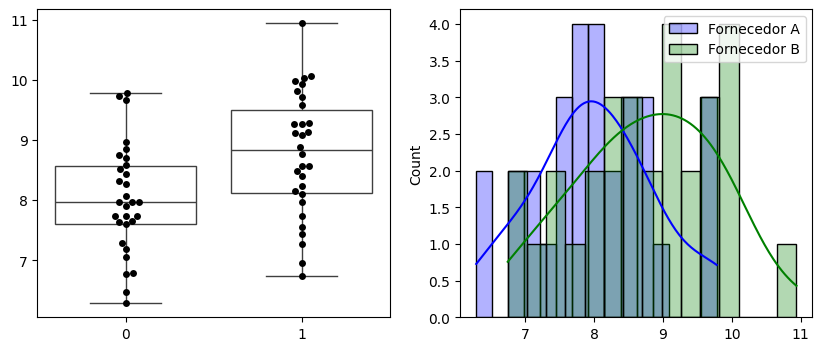

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
sns.boxplot(data=[baterias_A, baterias_B],color="white")
sns.swarmplot(data=[baterias_A, baterias_B],color="black")

plt.subplot(1, 2, 2)
sns.histplot(baterias_A, bins=15, kde=True, color='blue', label='Fornecedor A', alpha=0.3)
sns.histplot(baterias_B, bins=15, kde=True, color='green', label='Fornecedor B', alpha=0.3)

plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
baterias_A, baterias_B

(array([8.69671415, 8.0617357 , 8.84768854, 9.72302986, 7.96584663,
        7.96586304, 9.77921282, 8.96743473, 7.73052561, 8.74256004,
        7.73658231, 7.73427025, 8.44196227, 6.28671976, 6.47508217,
        7.63771247, 7.18716888, 8.51424733, 7.29197592, 6.7876963 ,
        9.66564877, 7.9742237 , 8.2675282 , 6.77525181, 7.65561728,
        8.31092259, 7.04900642, 8.57569802, 7.59936131, 7.90830625]),
 array([ 8.23812273, 10.937506  ,  8.88515305,  7.73651798,  9.8047994 ,
         7.55707199,  9.12974995,  6.74436286,  7.43899535,  9.11654736,
         9.71231324,  9.08850511,  8.77278689,  8.56878593,  7.27362581,
         8.10817137,  8.39329735, 10.06283445,  9.27798012,  6.96065583,
         9.25649237,  8.47640949,  8.1553858 ,  9.57284392, 10.03409947,
         9.92440813,  7.97686072,  8.55986639,  9.26438977,  9.97309964]))

In [ ]:
import scipy.stats as stats

# Teste t para amostras independentes (assumindo equal_var=True)
t_stat, p_valor = stats.ttest_ind(baterias_A, baterias_B, equal_var=True)

print("--- SOLUÇÃO EXERCÍCIO 1 (TESTE T INDEPENDENTE BILATERAL) ---")
print(f"Média A: {np.mean(baterias_A):.2f}h | Média B: {np.mean(baterias_B):.2f}h")
print(f"Estatística t: {t_stat:.4f} | p-valor: {p_valor:.4f}")

if p_valor < 0.05:
    print("Conclusão: Rejeita-se H0. Existe diferença estatisticamente significativa entre a autonomia das baterias dos dois fornecedores.")
else:
    print("Conclusão: Não se rejeita H0. Não há diferença significativa.")

--- SOLUÇÃO EXERCÍCIO 1 (TESTE T INDEPENDENTE BILATERAL) ---
Média A: 8.01h | Média B: 8.77h
Estatística t: -3.0324 | p-valor: 0.0036
Conclusão: Rejeita-se H0. Existe diferença estatisticamente significativa entre a autonomia das baterias dos dois fornecedores.


## Exercício 2: Tempo de Uso em Plataformas de Streaming

Um serviço de streaming investiga o tempo diário de reprodução (em minutos) de dois perfis de usuários: Usuários Mobile (30 pessoas) e Usuários de Smart TV (35 pessoas). Suspeita-se que os usuários de Smart TV possuam um comportamento de consumo muito mais disperso/variável do que os usuários de smartphone.

1. Execute o Teste de Levene para verificar se o pressuposto de homocedasticidade (igualdade de variâncias) foi violado a $\alpha = 0,05$.

2. Aplique o teste de hipóteses adequado (Teste t ou Teste t de Welch)  com significância $\alpha = 0,05$ para determinar se o tempo médio diário de uso difere entre as duas plataformas.

In [ ]:
#@markdown

np.random.seed(42)

# Mobile: menor variabilidade | Smart TV: alta variabilidade
tempo_mobile = np.random.normal(loc=45, scale=5, size=30)
tempo_smarttv = np.random.normal(loc=58, scale=20, size=35)

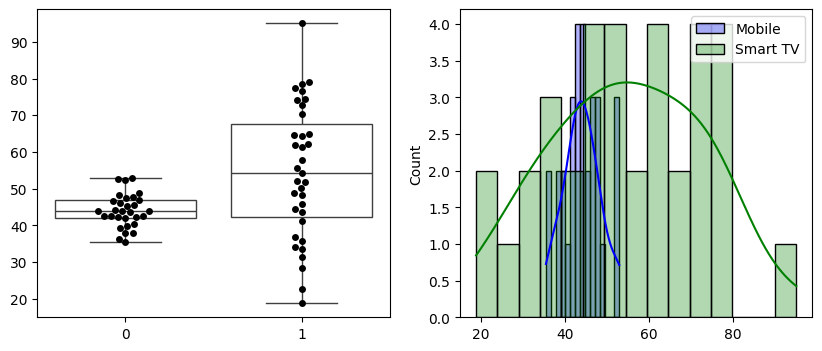

In [ ]:
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)

sns.boxplot(data=[tempo_mobile, tempo_smarttv],color="white")
sns.swarmplot(data=[tempo_mobile, tempo_smarttv],color="black")

plt.subplot(1, 2, 2)

sns.histplot(tempo_mobile, bins=15, kde=True, color='blue', label='Mobile', alpha=0.3)
sns.histplot(tempo_smarttv, bins=15, kde=True, color='green', label='Smart TV', alpha=0.3)

plt.legend()
plt.tight_layout()
plt.show()


In [ ]:
tempo_mobile, tempo_smarttv

(array([47.48357077, 44.30867849, 48.23844269, 52.61514928, 43.82923313,
        43.82931522, 52.89606408, 48.83717365, 42.65262807, 47.71280022,
        42.68291154, 42.67135123, 46.20981136, 35.43359878, 36.37541084,
        42.18856235, 39.9358444 , 46.57123666, 40.45987962, 37.93848149,
        52.32824384, 43.8711185 , 45.33764102, 37.87625907, 42.27808638,
        45.55461295, 39.24503211, 46.87849009, 41.99680655, 43.54153125]),
 array([45.96586776, 95.04556369, 57.73005551, 36.84578142, 74.45089824,
        33.583127  , 62.1772719 , 18.80659752, 31.43627902, 61.93722472,
        72.7693316 , 61.42736562, 55.68703435, 51.97792609, 28.42956019,
        43.60311583, 48.78722458, 79.14244452, 64.87236579, 22.73919689,
        64.48167939, 50.29835439, 44.46155999, 70.23352578, 78.61999045,
        76.62560238, 41.21564954, 51.81575248, 64.62526863, 77.51090254,
        48.41651524, 54.28682047, 35.87330052, 34.07586752, 74.25051645]))

In [ ]:
# 1. Teste de Igualdade de Variâncias (Levene)
stat_lev, p_lev = stats.levene(tempo_mobile, tempo_smarttv)

# 2. Teste t de Welch (equal_var=False)
t_stat, p_valor = stats.ttest_ind(tempo_mobile, tempo_smarttv, equal_var=False)

print("--- SOLUÇÃO EXERCÍCIO 2 (TESTE T DE WELCH) ---")
print(f"Desvio Padrão Mobile: {np.std(tempo_mobile, ddof=1):.2f} min | Smart TV: {np.std(tempo_smarttv, ddof=1):.2f} min")
print(f"Teste de Levene: estatística={stat_lev:.4f}, p-valor={p_lev:.4f}")
print(f"Welch t-test: estatística t={t_stat:.4f}, p-valor={p_valor:.4f}")

if p_valor < 0.05:
    print("Conclusão: Rejeita-se H0. O tempo médio diário de uso difere significativamente entre as plataformas.")
else:
    print("Conclusão: Não se rejeita H0.")


--- SOLUÇÃO EXERCÍCIO 2 (TESTE T DE WELCH) ---
Desvio Padrão Mobile: 4.50 min | Smart TV: 18.22 min
Teste de Levene: estatística=36.4052, p-valor=0.0000
Welch t-test: estatística t=-3.3365, p-valor=0.0019
Conclusão: Rejeita-se H0. O tempo médio diário de uso difere significativamente entre as plataformas.


# Flexibilidade em relação aos Pressupostos Estatísticos e suas Consequências

📚 Na prática científica e corporativa, os pressupostos teóricos (como Normalidade rigorosa e Homocedasticidade) raramente são satisfeitos com perfeição. Em geral, somos bastante "flexíveis" com relação aos pressupostos pela robustez dos testes e pela força do TCL que fazem com que pequenos desvios na distribuição não invalidem os testes. Grande desvios, entretanto, tendem a gerar falsos positivos (Erro Tipo I).





 # Teste de Welch como o padrão moderno

 📚 O Teste t de Student clássico assume variâncias populacionais iguais ($\sigma_1^2 = \sigma_2^2$), se por outro lado $\sigma_1^2 \neq \sigma_2^2$:

 1. $\sigma_1^2 > \sigma_2^2$, $n_1 < n_2$ (maior variância do grupo de menor amostra) $\longrightarrow$ Mais falsos positivos
 2. $\sigma_1^2 > \sigma_2^2$, $n_1 > n_2$ (maior variância do grupo de maior amostra) $\longrightarrow$ Mais falsos negativos

 O **Teste t de Welch** ajusta os graus de liberdade (por meio da fórmula de *Welch-Satterthwaite*). **Ele preserva rigorosamente a taxa nominal do Erro Tipo I ($\alpha = 0,05$) independentemente de as variâncias serem iguais ou diferentes, sem perda apreciável de poder estatístico quando as variâncias coincidem**.

## Exercício 3: Teste A/B de Checkout em E-commerce

Uma equipe de UX lançou um Teste A/B para avaliar o ticket médio gasto (em R$) em uma loja virtual. A Versão A utiliza o fluxo de pagamento tradicional, enquanto a Versão B traz um botão de Checkout Express. A empresa deseja implementar a Versão B em definitivo somente se ela aumentar significativamente o ticket médio.

1. Formule as hipóteses nula ($H_0$) e alternativa ($H_1$) do teste adequado para a tomada de decisão.

2. Com base nas amostras coletadas (40 transações na Versão A e 40 na Versão B), execute o teste com significância de $\alpha = 0,05$ e determine se a nova interface deve ser adotada.

In [ ]:
#@markdown

np.random.seed(42)

ticket_A = np.random.normal(loc=120.0, scale=25.0, size=40)
ticket_B = np.random.normal(loc=132.0, scale=25.0, size=40)

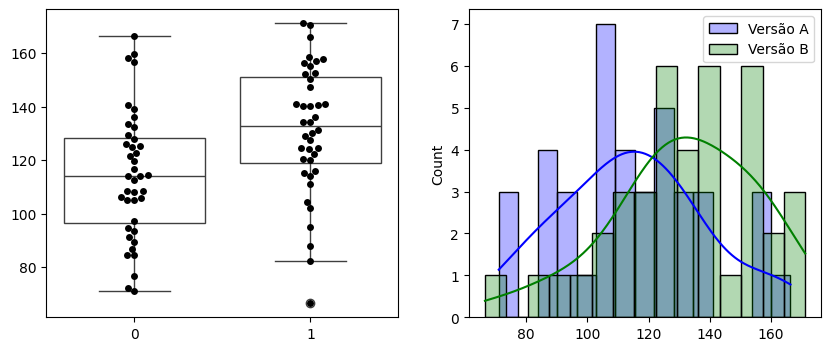

In [ ]:
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)

sns.boxplot(data=[ticket_A, ticket_B],color="white")
sns.swarmplot(data=[ticket_A, ticket_B],color="black")

plt.subplot(1, 2, 2)
sns.histplot(ticket_A, bins=15, kde=True, color='blue', label='Versão A', alpha=0.3)
sns.histplot(ticket_B, bins=15, kde=True, color='green', label='Versão B', alpha=0.3)

plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
ticket_A, ticket_B

(array([132.41785383, 116.54339247, 136.19221345, 158.07574641,
        114.14616563, 114.14657608, 159.48032039, 139.18586823,
        108.26314035, 133.56400109, 108.41455768, 108.35675616,
        126.04905679,  72.16799388,  76.87705419, 105.94281177,
         94.67922199, 127.85618331,  97.29939811,  84.69240747,
        156.64121922, 114.35559249, 121.68820512,  84.38129534,
        106.39043189, 122.77306474,  91.22516056, 129.39245046,
        104.98403275, 112.70765626, 104.95733469, 166.30695461,
        119.66256938,  93.55722678, 140.5636228 ,  89.47890875,
        125.22158988,  71.0082469 ,  86.79534878, 124.9215309 ]),
 array([150.4616645 , 136.28420703, 129.10879294, 124.47240761,
         95.03695024, 114.00389479, 120.48403073, 158.42805566,
        140.59045724,  87.92399612, 140.10209923, 122.37294299,
        115.07694999, 147.29190722, 157.77498806, 155.28200298,
        111.01956192, 124.2696906 , 140.28158579, 156.38862818,
        120.02064405, 127.35852558, 10

In [ ]:
# Teste unilateral: alternative='greater' testa se media(B) > media(A)
t_stat, p_valor = stats.ttest_ind(ticket_B, ticket_A, equal_var=True, alternative='greater')

print("--- SOLUÇÃO EXERCÍCIO 3 (TESTE A/B UNILATERAL) ---")
print(f"Ticket Médio A: R$ {np.mean(ticket_A):.2f} | Ticket Médio B: R$ {np.mean(ticket_B):.2f}")
print(f"Estatística t: {t_stat:.4f} | p-valor (unilateral): {p_valor:.4f}")

if p_valor < 0.05:
    print("Conclusão: Rejeita-se H0. A Versão B aumentou significativamente o ticket médio. A nova interface deve ser adotada!")
else:
    print("Conclusão: Não se rejeita H0. Não há evidência suficiente de aumento no ticket médio.")

--- SOLUÇÃO EXERCÍCIO 3 (TESTE A/B UNILATERAL) ---
Ticket Médio A: R$ 114.53 | Ticket Médio B: R$ 131.27
Estatística t: 3.1232 | p-valor (unilateral): 0.0013
Conclusão: Rejeita-se H0. A Versão B aumentou significativamente o ticket médio. A nova interface deve ser adotada!


## Exercício 4: Otimização de Performance de App Mobile

Uma equipe de desenvolvimento mobile lançou uma atualização de código para corrigir um gargalo de memória em seu aplicativo. Para validar o ganho de desempenho, mediu-se o tempo de inicialização do app (em segundos) em 20 modelos de smartphones diferentes, exatamente antes e depois da instalação do patch de correção6.

1. Defina o teste adequado para este problema.

2. Execute o teste selecionado com significância de  $\alpha = 0,05$ e determine se a atualização reduziu significativamente o tempo de inicialização do aplicativo.

In [ ]:
#@markdown
np.random.seed(42)

# 20 celulares diferentes (variabilidade natural grande entre modelos)
tempo_antes = np.random.normal(loc=4.5, scale=1.2, size=20)

# O mesmo celular após a correção (redução média de ~0.6s)
tempo_depois = tempo_antes - np.random.normal(loc=0.6, scale=0.3, size=20)

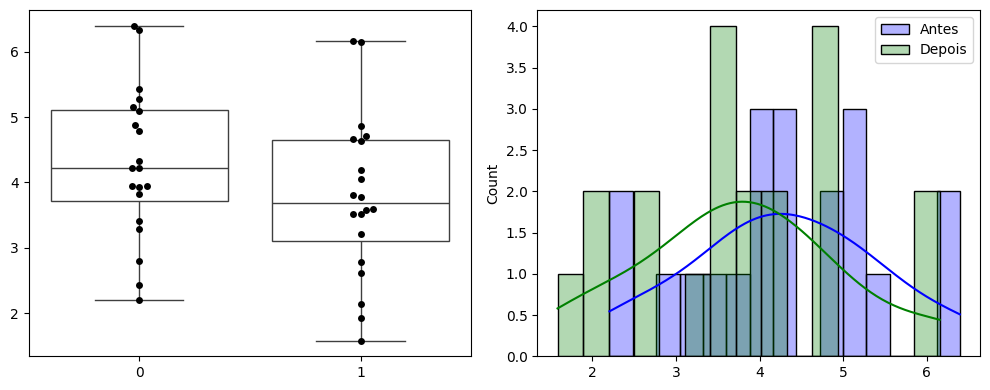

In [ ]:
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)

sns.boxplot(data=[tempo_antes, tempo_depois],color="white")
sns.swarmplot(data=[tempo_antes, tempo_depois],color="black")

plt.subplot(1, 2, 2)
sns.histplot(tempo_antes, bins=15, kde=True, color='blue', label='Antes', alpha=0.3)
sns.histplot(tempo_depois, bins=15, kde=True, color='green', label='Depois',alpha=0.3)

plt.legend()
plt.tight_layout()
plt.show()



In [ ]:
# Teste t pareado (ttest_rel)
t_stat, p_valor = stats.ttest_rel(tempo_antes, tempo_depois)

print("--- SOLUÇÃO EXERCÍCIO 4 (TESTE T PAREADO) ---")
print(f"Média Antes: {np.mean(tempo_antes):.2f}s | Média Depois: {np.mean(tempo_depois):.2f}s")
print(f"Diferença Média de Tempo: {np.mean(tempo_antes - tempo_depois):.2f}s")
print(f"Estatística t: {t_stat:.4f} | p-valor: {p_valor:.4e}")

if p_valor < 0.05:
    print("Conclusão: Rejeita-se H0. A otimização de código reduziu significativamente o tempo de carregamento do app!")
else:
    print("Conclusão: Não se rejeita H0.")

--- SOLUÇÃO EXERCÍCIO 4 (TESTE T PAREADO) ---
Média Antes: 4.29s | Média Depois: 3.77s
Diferença Média de Tempo: 0.52s
Estatística t: 8.0108 | p-valor: 1.6426e-07
Conclusão: Rejeita-se H0. A otimização de código reduziu significativamente o tempo de carregamento do app!


## Exercício 5: Eficiência de Canais de Aquisição de Clientes

Uma empresa de marketing digital quer comparar a taxa de conversão diária (%) obtida através de 3 canais de aquisição distintos: E-mail Marketing, Redes Sociais e Google Ads. Foram coletados os dados diários de conversão ao longo de 25 dias para cada um dos 3 canais.

1. Defina o teste de significância mais adequado para este caso e suas hipótese nula ($H_0$) e alternativa ($H_1$)

2. Execute o teste com significância $\alpha = 0,05$ e determine se existe diferença significativa na taxa de conversão entre os canais de aquisição.

In [ ]:
#@markdown

np.random.seed(42)

# Dados de conversão diária (%) para 3 canais
email_mkt = np.random.normal(loc=3.2, scale=0.8, size=25)
redes_sociais = np.random.normal(loc=3.8, scale=0.8, size=25)
google_ads = np.random.normal(loc=4.5, scale=0.8, size=25)


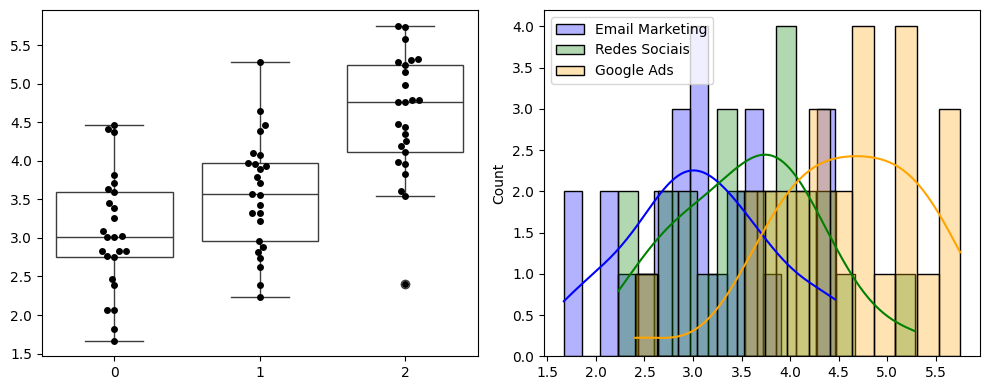

In [ ]:
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)

sns.boxplot(data=[email_mkt, redes_sociais, google_ads],color="white")
sns.swarmplot(data=[email_mkt, redes_sociais, google_ads],color="black")

plt.subplot(1, 2, 2)
sns.histplot(email_mkt, bins=15, kde=True, color='blue', label='Email Marketing', alpha=0.3)
sns.histplot(redes_sociais, bins=15, kde=True, color='green', label='Redes Sociais', alpha=0.3)
sns.histplot(google_ads, bins=15, kde=True, color='orange', label='Google Ads', alpha=0.3)

plt.legend()
plt.tight_layout()
plt.show()



In [ ]:
email_mkt, redes_sociais, google_ads

(array([3.59737132, 3.08938856, 3.71815083, 4.41842389, 3.0126773 ,
        3.01269043, 4.46337025, 3.81394778, 2.82442049, 3.63404803,
        2.82926585, 2.8274162 , 3.39356982, 1.6693758 , 1.82006573,
        2.75016998, 2.3897351 , 3.45139787, 2.47358074, 2.07015704,
        4.37251902, 3.01937896, 3.25402256, 2.06020145, 2.76449382]),
 array([3.88873807, 2.87920514, 4.10055841, 3.31948905, 3.566645  ,
        3.31863471, 5.28182255, 3.78920222, 2.95383126, 4.45803593,
        2.82332508, 3.96709088, 2.2322639 , 2.73745116, 3.95748899,
        4.39077326, 3.93709462, 3.70748137, 3.55911704, 2.61718241,
        3.22412463, 3.43148898, 4.64569778, 4.07489463, 2.38956788]),
 array([4.75926718, 4.19193418, 3.9584624 , 4.98934103, 5.32479962,
        5.2450241 , 3.82862598, 4.2526301 , 4.76501075, 5.2804361 ,
        4.11666061, 4.35147282, 3.61493202, 3.5430347 , 5.15002066,
        5.58499202, 4.4423919 , 5.30282632, 4.78930882, 3.9839042 ,
        4.78911648, 5.73042925, 4.47133917, 

In [ ]:
# One-Way ANOVA (f_oneway)
f_stat, p_valor = stats.f_oneway(email_mkt, redes_sociais, google_ads)

print("--- SOLUÇÃO EXERCÍCIO 5 (ANOVA UNIFATORIAL) ---")
print(f"Médias -> E-mail: {np.mean(email_mkt):.2f}% | Redes: {np.mean(redes_sociais):.2f}% | Ads: {np.mean(google_ads):.2f}%")
print(f"Estatística F: {f_stat:.4f} | p-valor: {p_valor:.4e}")

if p_valor < 0.05:
    print("Conclusão: Rejeita-se H0. Existe diferença estatisticamente significativa no desempenho de pelo menos um dos canais!")
else:
    print("Conclusão: Não se rejeita H0.")

--- SOLUÇÃO EXERCÍCIO 5 (ANOVA UNIFATORIAL) ---
Médias -> E-mail: 3.07% | Redes: 3.57% | Ads: 4.58%
Estatística F: 25.4486 | p-valor: 4.3699e-09
Conclusão: Rejeita-se H0. Existe diferença estatisticamente significativa no desempenho de pelo menos um dos canais!


# Por que NÃO usar testes t dois a dois ao comparar múltiplos grupos?

📚 Ao comparar 3 ou mais grupos (por exemplo, Canais A, B e C) podemos não aplicar múltiplos testes t independentes dois a dois (A $\times$ B, A $\times$ C, B $\times$ C)? **Não**. Isso é metodologicamente errado devido a um fenômeno denominado **Inflação do Erro Família / Erro Acumulado (Family-wise Error Rate - FWER)**.


> A probabilidade de cometer pelo menos um falso positivo ($\alpha_{FW}$) é dada por:

$$\alpha_{FW} = 1 - (1 - \alpha)^k$$

> Onde $k = \frac{m(m - 1)}{2}$ é o número de combinações par a par para $m$ grupos.

> Assim,
> - 2 grupos, $\alpha_{FW} = 0.05 = (5\%)$
> - 3 grupos, $\alpha_{FW} = 0.143 = (14.3\%)$
> - 4 grupos, $\alpha_{FW} = 0.4013 = (40.1\%)$
...

> Aumentando enormemente o erro Tipo I (Falsos Positivos).

A ANOVA Unifatorial resolve a inflação do erro avaliando a variabilidade entre os grupos em relação à variabilidade dentro dos grupos em um único teste estatístico global (*Omnibus Test*), mantendo o Erro Tipo I global rigorosamente fixado no nível nominal $\alpha = 0,05$. **Somente se a ANOVA rejeitar a hipótese nula ($p < 0,05$), autoriza-se a aplicação de testes *post-hoc*** com correção para comparações múltiplas (como o teste de Tukey HSD ou Bonferroni) para identificar com precisão quais pares de grupos diferem entre si.